# 05. Readout-power dependence and the line attenuation

The probe tone stores energy in the resonator, and the RF current that this energy drives through the
termination inductor puts an RF flux $\Phi_\mathrm{rf}$ into the SQUID. Averaged over the RF cycle the SQUID
then screens differently than at zero power (the "dressing" described by the Wegner series), so the flux
modulation of the resonance changes with the readout power, by an amount that depends on the flux bias. The
model computes this from the instantaneous stored energy $|a|^2$ with device parameters extracted at a single
power, and this notebook tests that prediction against a VNA sweep of resonator 2 at 16 output powers (paper
Sec. V A, Fig. 7). One number is fitted: the power scale $A$ from the VNA output to the chip, nominally the line
attenuation, which the other notebooks use to convert instrument powers to powers at the chip and which also
absorbs any error in the absolute size of $\Phi_\mathrm{rf}$ (step 3). Data:
`data/vna/res2_flux_power_sweep_2026-09-26.npz` and the configuration `configs/nist_res2_2026-09-26.toml`,
extracted from the same sweep at a single power (notebook 01); the notebook runs in about a minute, 40 s of which
is the CMT grid of step 2.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

import time
from scipy.optimize import least_squares

SWEEP = DATA / "vna" / "res2_flux_power_sweep_2026-09-26.npz"
CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"
FLUX = [0.0, 0.25, 0.5]                  # nominal Phi0; the nearest sweep points are used
P_SIM = np.arange(-110, -62.5, 1.0)      # dBm at the chip, the powers of the CMT grid
M_NOMINAL = 14.4e-12                     # H, the mutual the flux axis of the sweep was programmed with
A_NOMINAL = -61.0                        # dB, the discrete attenuators between the VNA and the chip

## 1. The measured resonance at every power

The sweep holds $S_{21}$ at 16 VNA output powers ($-40$ to $-10$ dBm in 2 dB steps) and 101 flux biases
$\Phi_\mathrm{ext}$ applied through the flux-ramp line. We take the biases nearest $0$, $0.25$ and $0.5\,\Phi_0$
(the sweep has $0.24$): the first two lie on either side of the broad maximum of the flux modulation, the third
on the steep flank that leads into its sharp minimum. At every power $f_r$ comes from the same circle fit as in
notebook 01 (`fit_resonance_trace`: the cable delay from the edges of the sweep with the fitted notch divided
out, then the notch fit of Probst et al. within 1.5 MHz of the dip), not from the minimum of $|S_{21}|$, so that
$f_r$ keeps one meaning when the lineshape turns asymmetric at high power.

In [2]:
sweep = uc.load_vna_sweep(SWEEP)
j_flux = [sweep.flux_index(x) for x in FLUX]
flux, P_vna = sweep.flux[j_flux], sweep.powers
I_bias = sweep.bias_current(M_NOMINAL)[j_flux]

t0 = time.perf_counter()
fits = [[uc.fitting.fit_resonance_trace(sweep.f, sweep.s21[k, j]) for k in range(len(P_vna))] for j in j_flux]
fr_meas = np.array([[fit.fr for fit in row] for row in fits])
print(f"{fr_meas.size} circle fits in {time.perf_counter() - t0:.1f} s\n")

lo, hi = f"fr at {P_vna[0]:.0f} dBm", f"fr at {P_vna[-1]:.0f} dBm"
print(f"{'flux (Phi0)':>11} {'I (uA)':>7} {lo + ' (MHz)':>20} {hi + ' (MHz)':>20} {'span (kHz)':>11} {'median Qr':>10}")
for x, I, row, fl in zip(flux, I_bias, fr_meas, fits):
    print(f"{x:11.2f} {I * 1e6:7.1f} {row[0] / 1e6:20.4f} {row[-1] / 1e6:20.4f} {np.ptp(row) / 1e3:11.1f} "
          f"{np.median([fit.Qr for fit in fl]):10.0f}")

48 circle fits in 0.7 s

flux (Phi0)  I (uA)  fr at -40 dBm (MHz)  fr at -10 dBm (MHz)  span (kHz)  median Qr
       0.00     0.0            5515.9642            5515.7946       169.6       9588
       0.24    34.5            5515.9970            5515.8428       154.2       9559
       0.50    71.8            5515.5166            5515.5639        84.4       9385


## 2. The same sweeps from the model

For each bias the flux-ramp line carries the current the measurement applied, $I = n\,\Phi_0/M_\mathrm{nom}$ for
a nominal bias of $n\,\Phi_0$ ($M_\mathrm{nom} = 14.4$ pH), and the fitted $M_\mathrm{fr}$ of the configuration
turns it into flux as the real coil did. `steady_state_sweep` then plays VNA over 3.5 MHz around the zero-power
resonance at every chip power from $-110$ to $-63$ dBm in 1 dB steps. Each simulated trace is fitted with the same
notch model as the measured ones, but with a simpler recipe: `refined_fit` with $\tau = 0$ over the whole simulated
span, since the virtual VNA has no cable delay to iterate on. This is an out-of-sample test: all device parameters
are fixed by the configuration, extracted at a single power ($-26$ dBm at the VNA, $-89$ dBm at the chip), and how
$f_r$ moves with power at each bias follows from $\Phi_\mathrm{rf} = M_c I_T(|a|^2)$ and the dressed screening
response; only the overall power scale is left to step 3. (One known systematic: $\lambda$ and $M_c$ fitted at
$-89$ dBm already carry the dressing at that power, which the model applies a second time; the paper finds that
undressed parameters change the rms residual of step 3 by about 2 kHz and $A$ by 0.4 dB.) The grid is 3 biases
$\times$ 48 powers $\times$ 351 frequencies, about 50,000 steady-state solves, and this cell takes about 40 s.

In [3]:
cfg = uc.Config(CONFIG)
device = cfg.build()
ch = device[0]
ramp = ch.line("FluxRamp")
f0 = ch.f0
print(device.summary())
print(f"\nextracted at {cfg.P_rf_dBm:.1f} dBm at the chip; fitted Mfr = {ramp.M * 1e12:.2f} pH "
      f"(nominal {M_NOMINAL * 1e12:.1f} pH)")

t0 = time.perf_counter()
f_sim, s21_sim, fr_sim = [], [], np.zeros((len(flux), len(P_SIM)))
for j, I in enumerate(I_bias):
    ramp.I = I
    fr_lin = ch.get_fr(0.0)
    ramp.I = 0.0
    f = np.linspace(fr_lin - 2e6, fr_lin + 1.5e6, 351)
    s21 = np.array([uc.steady_state_sweep(device, f, P, flux_ramp_current=I) for P in P_SIM])
    fr_sim[j] = [uc.fitting.refined_fit(f, s, tau=0)[2] for s in s21]
    f_sim.append(f)
    s21_sim.append(s21)
f_sim, s21_sim = np.array(f_sim), np.array(s21_sim)
t_grid = time.perf_counter() - t0
print(f"\nCMT grid: {fr_sim.size} sweeps x {f_sim.shape[1]} frequencies = {s21_sim.size} steady-state solves "
      f"in {t_grid:.0f} s")

nist_res2_2026-09-26: 1 channel(s), Z0 = 50 Ohm
 ch   f0 (MHz)      Qr      Qc        Qi   alpha   lamb  Mc (pH)  BW (kHz)
  0   5515.689    9515   10475    103803  -0.086  0.318     3.69       580

extracted at -88.9 dBm at the chip; fitted Mfr = 14.41 pH (nominal 14.4 pH)



CMT grid: 144 sweeps x 351 frequencies = 50544 steady-state solves in 35 s


## 3. One fitted number: the attenuation $A$

A VNA output power $P_\mathrm{VNA}$ reaches the chip as $P_\mathrm{VNA} + A$, with $A$ nominally the loss of the
input line: $-61$ dB of discrete attenuators plus cables and connectors. $A$ is the only parameter fitted in this
notebook: the measured shifts $f_r - f_0$ of all 48 points (3 biases $\times$ 16 powers) are compared with the
simulated curve of their bias interpolated at $P_\mathrm{VNA} + A$, and the sum of squared residuals is minimised.
Both shifts are referenced to the bare $f_0$ of the configuration (the resonance with the SQUID unloaded).

In [4]:
shift_meas, shift_sim = (fr_meas - f0) / 1e3, (fr_sim - f0) / 1e3        # kHz
rms = lambda r: np.sqrt(np.mean(np.asarray(r) ** 2))

def predict(A, j):
    return np.interp(P_vna + A, P_SIM, shift_sim[j])

def residuals(A, js=range(len(flux))):
    return np.concatenate([predict(A[0], j) - shift_meas[j] for j in js])

fit = least_squares(residuals, x0=[A_NOMINAL])
A = fit.x[0]
A_err = np.sqrt(np.sum(fit.fun ** 2) / (fit.fun.size - 1) / (fit.jac.T @ fit.jac)[0, 0])

A_text = f"{A:.2f} +/- {A_err:.2f}"
print(f"{'':>20} {'A (dB)':>15} {'rms residual (kHz)':>19}   ({fit.fun.size} points)")
print(f"{'fitted (stat. error)':>20} {A_text:>15} {rms(fit.fun):19.1f}")
print(f"{'nominal attenuators':>20} {A_NOMINAL:15.2f} {rms(residuals([A_NOMINAL])):19.1f}")
print(f"\nthe sweep reached the chip at {P_vna[0] + A:.1f} to {P_vna[-1] + A:.1f} dBm")

store.record("Atten", A, "{:.1f}", "dB; instrument power + Atten = power at the chip (an effective scale that also "
             "absorbs errors in the RF-flux conversion). Fitted here, used by the other notebooks")
store.record("AttenErr", A_err, "{:.1f}", "dB, statistical uncertainty of Atten from the Jacobian of the fit; systematics are larger")
store.record("PowerRms", rms(fit.fun), "{:.1f}", "kHz, rms residual of fr over 3 fluxes x 16 powers at the fitted attenuation")
print(f"recorded: Atten {store.text('Atten')} dB, AttenErr {store.text('AttenErr')} dB, PowerRms {store.text('PowerRms')} kHz")

                              A (dB)  rms residual (kHz)   (48 points)
fitted (stat. error) -62.90 +/- 0.08                 5.7
 nominal attenuators          -61.00                23.4

the sweep reached the chip at -102.9 to -72.9 dBm
recorded: Atten -62.9 dB, AttenErr 0.1 dB, PowerRms 5.7 kHz


The fitted $A$ lies about 2 dB beyond the $-61$ dB of attenuators, a plausible cable loss, but $A$ is more than a
cable loss. The stored energy enters the model only through the RF flux
$\Phi_\mathrm{rf} = M_c I_T \propto M_c\sqrt{P_\mathrm{chip}}$ (`Channel.get_Phi_rf`), so changing $A$ by $\delta$ dB
is exactly equivalent to scaling $\Phi_\mathrm{rf}$ by $10^{\delta/20}$, and any error in that conversion lands in
$A$: in $M_c$, which the zero-power flux response fixes only together with $L_s$ ($M_c \propto \sqrt{L_s}$, so the
design $L_s = 22.4$ pH instead of the assumed 24.2 pH would move $A$ by $+0.34$ dB with identical residuals), or in
the prefactor of $I_T^2$ (the conventions of Wegner et al. and Kempf et al. differ by a factor 4, i.e. 6 dB). The
value of $A$ is therefore a sanity check of the absolute RF-flux scale, not a measurement of the attenuation; what
the 48 points test out of sample is the shape of $f_r(P)$ at each bias, with one power scale shared by all three
(checked in step 5).

The $\pm$ on $A$ is statistical only, from the Jacobian and the scatter of the residuals, and those residuals are
correlated (a static offset at low power, a trend at high power; step 5). Systematic shifts are larger: about
0.1 dB when a constant frequency offset is fitted as well (see *What to try next*), and 0.4 dB with undressed
device parameters (paper).

With $A$ known, measured and simulated traces can be compared at the same chip power. At zero flux bias the dip
moves about 170 kHz towards $f_0$ between the lowest and the highest power and leans towards low frequency, steeper
on its low-frequency side: the stored energy, and with it the dressing that pulls the resonance down, is largest
when the probe sits on resonance, as in a softening Duffing oscillator. The measured traces are shown with the
cable delay removed and divided by the fitted off-resonance level; the simulated ones are the grid powers nearest
to $P_\mathrm{VNA} + A$. The colour is that of this bias in the next figure, darker for higher power.

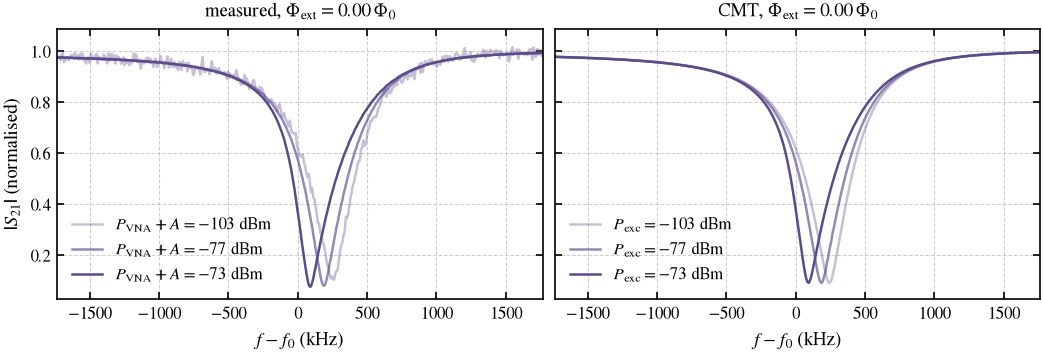

In [5]:
j, k_show = 0, [0, 13, len(P_vna) - 1]
fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.4), sharey=True)
for k, shade in zip(k_show, (0.35, 0.65, 1.0)):
    meas = fits[j][k]
    k_sim = np.argmin(np.abs(P_SIM - (P_vna[k] + A)))
    axes[0].plot((sweep.f - f0) / 1e3, np.abs(meas.s21_corrected) / meas.a, color=ORDERED_3[j], alpha=shade,
                 label=rf"$P_\mathrm{{VNA}} + A = {P_vna[k] + A:.0f}$ dBm")
    axes[1].plot((f_sim[j] - f0) / 1e3, np.abs(s21_sim[j, k_sim]), color=ORDERED_3[j], alpha=shade,
                 label=rf"$P_\mathrm{{exc}} = {P_SIM[k_sim]:.0f}$ dBm")
for ax, title in zip(axes, ["measured", "CMT"]):
    ax.set_xlim((f_sim[j][0] - f0) / 1e3, (f_sim[j][-1] - f0) / 1e3)
    ax.set_xlabel(r"$f - f_0$ (kHz)")
    ax.set_title(rf"{title}, $\Phi_\mathrm{{ext}} = {flux[j]:.2f}\,\Phi_0$")
    ax.legend(loc="lower left")
    grid(ax)
axes[0].set_ylabel(r"$|S_{21}|$ (normalised)")
save(fig, "05_lineshapes", RESULTS / "figures")
plt.show()

## 4. Resonance shift against chip power (Fig. 7)

Lines are the simulated grid, open markers the measured resonances placed at $P_\mathrm{VNA} + A$, and the lower
panel shows the residuals. The dressing suppresses the flux harmonics of the screening response, the higher ones
first: near the top of the modulation ($0$ and $0.24\,\Phi_0$) the resonance falls steadily towards $f_0$, while on
the flank near the sharp minimum ($0.5\,\Phi_0$) it first moves further away as the minimum broadens, by 37 kHz in
the measurement (deepest at $-79$ dBm) but by only 31 kHz in the model (deepest at $-80$ dBm), and then rises.
Above the measured range (shaded) the model is unvalidated; there it predicts that the modulation passes through
zero near $-69$ dBm, where the RF flux reaches about $0.6\,\Phi_0$ and the fundamental of the screening response,
proportional to $J_1(\phi_\mathrm{rf})/\phi_\mathrm{rf}$ with $\phi_\mathrm{rf} = 2\pi\Phi_\mathrm{rf}/\Phi_0$,
changes sign. The curves bend sharply there, so for the figure only the model is also run half-way between the
grid powers above $-72$ dBm (27 more sweeps, about 10 s).

27 sweeps half-way between the grid powers in 8 s


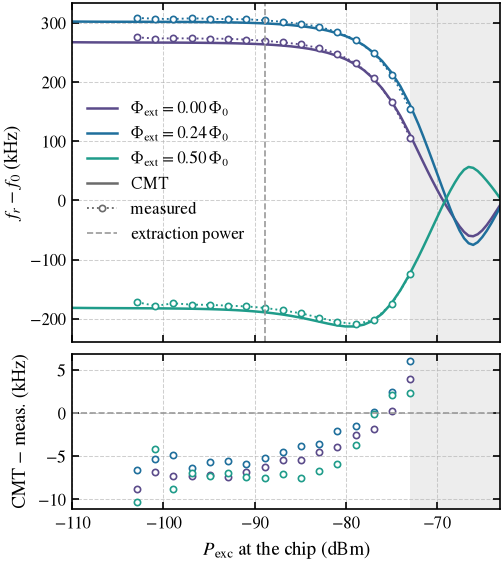

In [6]:
def shift_cmt(f, P, I):
    s21 = uc.steady_state_sweep(device, f, P, flux_ramp_current=I)
    return (uc.fitting.refined_fit(f, s21, tau=0)[2] - f0) / 1e3

P_mid = np.arange(-71.5, P_SIM[-1], 1.0)
t0 = time.perf_counter()
shift_mid = np.array([[shift_cmt(f, P, I) for P in P_mid] for f, I in zip(f_sim, I_bias)])
print(f"{shift_mid.size} sweeps half-way between the grid powers in {time.perf_counter() - t0:.0f} s")
order = np.argsort(np.concatenate([P_SIM, P_mid]))
P_line = np.concatenate([P_SIM, P_mid])[order]
shift_line = np.concatenate([shift_sim, shift_mid], axis=1)[:, order]

colors = ORDERED_3 if len(flux) <= 3 else COLORS
fig, (ax, axr) = plt.subplots(2, 1, figsize=(SINGLE, 3.8), sharex=True, height_ratios=[2.2, 1])
for j, (x, c) in enumerate(zip(flux, colors)):
    ax.plot(P_line, shift_line[j], color=c, label=rf"$\Phi_\mathrm{{ext}} = {x:.2f}\,\Phi_0$")
    ax.plot(P_vna + A, shift_meas[j], ":o", color=c, mfc="white", mew=0.8, lw=0.9)
    axr.plot(P_vna + A, predict(A, j) - shift_meas[j], "o", color=c, mfc="white", mew=0.8)
ax.plot([], [], color=GRAY, label="CMT")
ax.plot([], [], ":o", color=GRAY, mfc="white", mew=0.8, lw=0.9, label="measured")
ax.axvline(cfg.P_rf_dBm, color=ZERO, ls="--", lw=0.8, label="extraction power")
for panel in (ax, axr):
    panel.axvspan(P_vna[-1] + A, P_SIM[-1], color=GRAY, alpha=0.12, lw=0)
    grid(panel)
axr.axhline(0, color=ZERO, ls="--", lw=0.8)
ax.set_xlim(P_SIM[0], P_SIM[-1])
ax.set_ylabel(r"$f_r - f_0$ (kHz)")
ax.legend(loc="center left")
axr.set_ylabel("CMT $-$ meas. (kHz)")
axr.set_xlabel(r"$P_\mathrm{exc}$ at the chip (dBm)")
save(fig, "05_power_dependence", RESULTS / "figures")
plt.show()

## 5. How much of the power dependence does the model explain?

Per flux bias: the **span** of the measured shift over the 30 dB of power, which is the size of the effect; the
residual of a model with **no power dependence** (the simulated $f_r$ at the lowest measured power, held at every
power), which is the signal to be explained; the **CMT** residual and the ratio **CMT/none**, the fraction left
unexplained; and a check that one power scale serves every bias: **A from others**, fitted on the other two biases
only, and the **held-out CMT** residual of this bias predicted with it. The totals are the numbers the paper
quotes, with the CMT residual also as a fraction of the linewidth $f_0/Q_r$.

In [7]:
lw = ch.linewidth / 1e3                                                   # kHz
others = lambda j: [i for i in range(len(flux)) if i != j]

res_none, res_held = [], []
print(f"{'flux (Phi0)':>11} {'span (kHz)':>10} {'no P-dep. (kHz)':>15} {'CMT (kHz)':>9} {'CMT/none':>8} "
      f"{'A from others (dB)':>18} {'held-out CMT (kHz)':>18}")
for j, x in enumerate(flux):
    res_none.append(predict(A, j)[0] - shift_meas[j])
    res_cmt = predict(A, j) - shift_meas[j]
    A_j = least_squares(residuals, x0=[A], args=(others(j),)).x[0]
    res_held.append(predict(A_j, j) - shift_meas[j])
    print(f"{x:11.2f} {np.ptp(shift_meas[j]):10.1f} {rms(res_none[j]):15.1f} {rms(res_cmt):9.1f} "
          f"{rms(res_cmt) / rms(res_none[j]):8.0%} {A_j:18.2f} {rms(res_held[j]):18.1f}")

rms_cmt, rms_none, rms_held = rms(fit.fun), rms(np.concatenate(res_none)), rms(np.concatenate(res_held))
print(f"\nall {fit.fun.size} points: CMT {rms_cmt:.1f} kHz ({rms_cmt / lw:.1%} of the {lw:.0f} kHz linewidth), "
      f"no power dependence {rms_none:.1f} kHz, unexplained {rms_cmt / rms_none:.0%}, "
      f"held out by flux {rms_held:.1f} kHz, worst point {np.abs(fit.fun).max():.1f} kHz")

low = P_vna + A < -85
offset = [np.mean(predict(A, j)[low] - shift_meas[j][low]) for j in range(len(flux))]
print("mean CMT - measured below -85 dBm: " + ", ".join(f"{o:+.1f}" for o in offset) + " kHz; "
      f"notebook 04 at the extraction power: {store.value('SfrOff', default=-6.7):+.1f} kHz")

store.record("PowerRmsLw", 100 * rms_cmt / lw, "{:.1f}", "%, the CMT residual of the power dependence as a fraction of the linewidth")
store.record("PowerNone", rms_none, "{:.0f}", "kHz, rms residual if the resonance had no power dependence")
store.record("PowerUnexplained", 100 * rms_cmt / rms_none, "{:.0f}", "%, fraction of the power dependence left by the CMT")
store.record("PowerHeld", rms_held, "{:.1f}", "kHz, rms residual with the attenuation fitted on the other two fluxes")
store.record("PowerSpan", np.ptp(shift_meas, axis=1).max(), "{:.0f}", "kHz, largest measured span of fr over the 30 dB of power")
print("recorded: " + ", ".join(f"{name} {store.text(name)}" for name in
                               ("PowerRmsLw", "PowerNone", "PowerUnexplained", "PowerHeld", "PowerSpan")))

flux (Phi0) span (kHz) no P-dep. (kHz) CMT (kHz) CMT/none A from others (dB) held-out CMT (kHz)
       0.00      169.6            51.1       5.8      11%             -62.90                5.8
       0.24      154.2            46.2       4.7      10%             -62.96                4.9
       0.50       84.4            18.8       6.5      34%             -62.85                6.6

all 48 points: CMT 5.7 kHz (1.0% of the 580 kHz linewidth), no power dependence 41.2 kHz, unexplained 14%, held out by flux 5.8 kHz, worst point 10.3 kHz
mean CMT - measured below -85 dBm: -7.0, -5.5, -7.4 kHz; notebook 04 at the extraction power: -6.7 kHz
recorded: PowerRmsLw 1.0, PowerNone 41, PowerUnexplained 14, PowerHeld 5.8, PowerSpan 170


The model leaves about a seventh of the measured shift unexplained, and $A$ fitted on two biases predicts the
third almost as well as the joint fit: one power scale serves all three biases, so $A$ is not absorbing an error
that depends on the flux. The unexplained fraction is largest at $0.5\,\Phi_0$, where the effect is smallest and
the model's dip falls 6 kHz short of the measured one (step 4). Most of what is left is static: below $-85$ dBm,
where the probe hardly dresses the SQUID, the model sits 5.5 to 7.4 kHz below the measurement at all three biases,
close to the offset notebook 04 finds at the extraction power (the paper traces $-3.8$ kHz of it to the
flux-response fit and the rest to the second dressing of step 2). With $A$ as the only free parameter, the fit
balances that offset against the steep high-power end, where the residuals turn positive; these correlated
residuals are why the statistical error of $A$ understates its uncertainty.

## 6. Run time

The grid is the expensive part of this notebook. One 351-point sweep with its circle fit is timed at the lowest
and at the highest power of the grid (the solver takes more steps at high power, where the stored energy moves the
resonance most), as the median of three runs, and scaled to the 144 sweeps of the grid; a CPU time equal to the
wall time confirms that the solver runs on one core. This cell takes about 2 s.

In [8]:
def median_run_time(fn, repeats=3):
    wall, cpu = [], []
    for _ in range(repeats):
        t0, c0 = time.perf_counter(), time.process_time()
        fn()
        wall.append(time.perf_counter() - t0)
        cpu.append(time.process_time() - c0)
    return float(np.median(wall)), float(np.median(cpu))

I, f = I_bias[-1], f_sim[-1]
per_sweep = {}
for P in (P_SIM[0], P_SIM[-1]):
    wall, cpu = median_run_time(lambda: shift_cmt(f, P, I))
    per_sweep[P] = wall
    print(f"{P:.0f} dBm: {len(f)}-point sweep and fit {wall:.2f} s wall, {wall / len(f) * 1e3:.2f} ms per point "
          f"(CPU/wall = {cpu / wall:.2f})")
t_est = fr_sim.size * np.mean(list(per_sweep.values()))
print(f"grid of {fr_sim.size} sweeps ({s21_sim.size} steady-state points): about {t_est:.0f} s estimated, "
      f"{t_grid:.0f} s measured in step 2")

store.record("TimePowerGrid", t_est, "{:.0f}", "s, wall time of the 3 x 48 x 351 steady-state grid on one core, scaled from single sweeps")
store.record("NPowerPoints", s21_sim.size, "{:d}", "steady-state points in the power grid")
print(f"recorded: TimePowerGrid {store.text('TimePowerGrid')} s, NPowerPoints {store.text('NPowerPoints')}")

-110 dBm: 351-point sweep and fit 0.17 s wall, 0.50 ms per point (CPU/wall = 1.00)


-63 dBm: 351-point sweep and fit 0.32 s wall, 0.91 ms per point (CPU/wall = 1.00)
grid of 144 sweeps (50544 steady-state points): about 36 s estimated, 35 s measured in step 2
recorded: TimePowerGrid 36 s, NPowerPoints 50544


## What to try next

* **More flux biases.** `FLUX` takes any of the 101 sweep points over two flux quanta. Add $0.64\,\Phi_0$, the
  sharp minimum of the modulation, where the higher flux harmonics that the dressing removes first are largest,
  and see how $A$ and the residual per bias respond.
* **How firm is $A$?** Fit a constant frequency offset together with $A$,
  `least_squares(lambda p: np.concatenate([predict(p[0], j) + p[1] - shift_meas[j] for j in range(len(flux))]), x0=[A, 0])`:
  the rms residual falls to about 3 kHz and $A$ moves by about 0.1 dB, more than its statistical error. For a
  rough version of the paper's undressed-parameter check (0.4 dB), extract the configuration from the $-40$ dBm
  traces, where the SQUID is less dressed ($-103$ dBm at the chip): set `P_EXTRACT = -40` in notebook 01, which
  then writes `results/configs/nist_res2_2026-09-26.toml` (and overwrites its recorded values; rerun it with $-26$
  afterwards), point `CONFIG` at that file and rerun this notebook. Those parameters still carry some dressing, so
  do not expect the paper's number exactly.
* **Your own device.** Any VNA power sweep in the `.npz` layout of `uc.io.load_vna_sweep` (see `data/README.md`)
  and a configuration from notebook 01 run through this notebook unchanged; set `A_NOMINAL` to your attenuator
  chain and widen `P_SIM` if your sweep reaches higher powers at the chip.